In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('/content/sample_data/superstore.csv', encoding='latin-1')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [67]:
df.head(3)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


**Which states have the most sales?**



In [28]:
states_sales = df.groupby('State')[['Sales','Profit']].sum().sort_values(by = 'Sales', ascending=False).reset_index()
states_sales.shape

(49, 3)

In [29]:
states_sales.head()

,State,Sales,Profit
0,California,457687.6315,76381.3871
1,New York,310876.2710,74038.5486
2,Texas,170188.0458,-25729.3563
3,Washington,138641.2700,33402.6517
4,Pennsylvania,116511.9140,-15559.9603


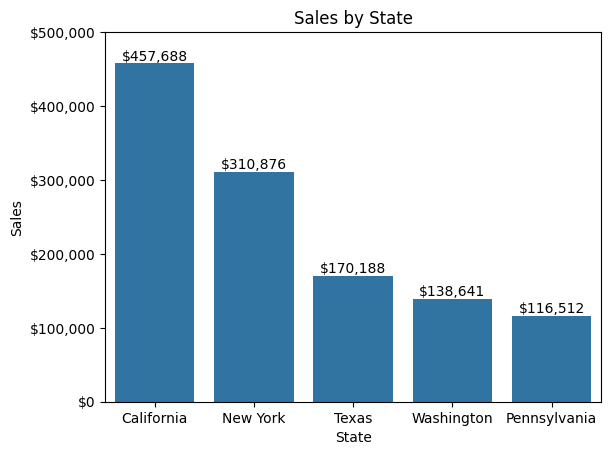

In [62]:
ax = sns.barplot(x='State', y='Sales', data=states_sales.head(5))

for container in ax.containers:
    ax.bar_label(container, fmt = '${:,.0f}')

# alternatively, without for-loop: ax.bar_label(ax.containers[0], fmt='${:,.0f}')

# plt.xticks(rotation=90)
plt.xlabel('State')
plt.ylabel('Sales')

# formatting y-ticks
yticks = ax.get_yticks()
ax.set_yticks(yticks) # Keeps current tick locations
ax.set_yticklabels([f"${y:,.0f}" for y in yticks])
## alternatively for sns.barplot:
# import matplotlib.ticker as mtick
# ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))

plt.title('Sales by State')
plt.show()

**What is the difference between New York and California in terms of sales and profit?** (Compare the total sales and profit between New York and California.)

 difference betyween CA and NY in Sales: $146,811.36
 difference betyween CA and NY in Profit: $2,342.84



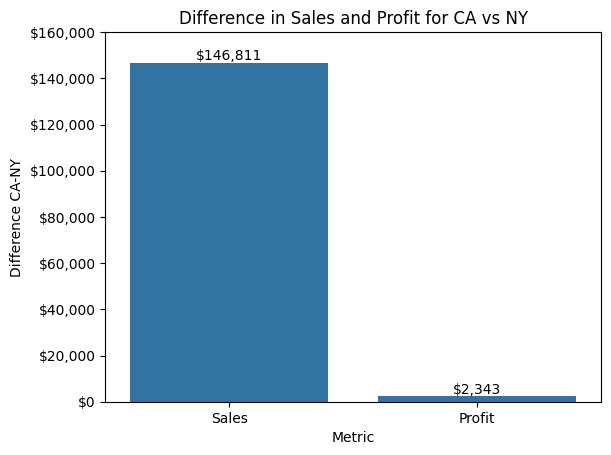

In [65]:
# difference betweek California and NY in Sales:
CA_NY_diff_sales = states_sales[states_sales['State'] == 'California']['Sales'].values[0] - states_sales[states_sales['State'] == 'New York']['Sales'].values[0]
print(f" difference betyween CA and NY in Sales: ${CA_NY_diff_sales:,.2f}")

# difference betweek California and NY in Profit:
CA_NY_diff_profit = states_sales[states_sales['State'] == 'California']['Profit'].values[0] - states_sales[states_sales['State'] == 'New York']['Profit'].values[0]
print(f" difference betyween CA and NY in Profit: ${CA_NY_diff_profit:,.2f}\n")

diff = [CA_NY_diff_sales,CA_NY_diff_profit]
metric = ['Sales', 'Profit']

# Visualization as barplot
ax = sns.barplot(x=metric, y=diff)
ax.bar_label(ax.containers[0], fmt = '${:,.0f}')

# plt.xticks(rotation=90)
plt.xlabel('Metric')

# formatting y-ticks
yticks = ax.get_yticks()
ax.set_yticks(yticks) # Keeps current tick locations
ax.set_yticklabels([f"${y:,.0f}" for y in yticks])

plt.ylabel('Difference CA-NY')
plt.title('Difference in Sales and Profit for CA vs NY')
plt.show()

**Who is an outstanding customer in New York?**

In [104]:
customer_sales = df[df['State'] == 'New York'].groupby(['Customer ID','Customer Name','State'])[['Sales','Profit']].sum().sort_values(by = 'Sales', ascending=False).reset_index()
customer_sales[customer_sales['State'] == 'New York'].head()

,Customer ID,Customer Name,State,Sales,Profit
0,TA-21385,Tom Ashbrook,New York,13723.498,4599.2073
1,PF-19120,Peter Fuller,New York,7678.228,543.2819
2,SV-20365,Seth Vernon,New York,7359.918,1571.7964
3,TB-21400,Tom Boeckenhauer,New York,6999.960,2239.9872
4,GT-14710,Greg Tran,New York,6712.744,774.7935


total of 415 customers


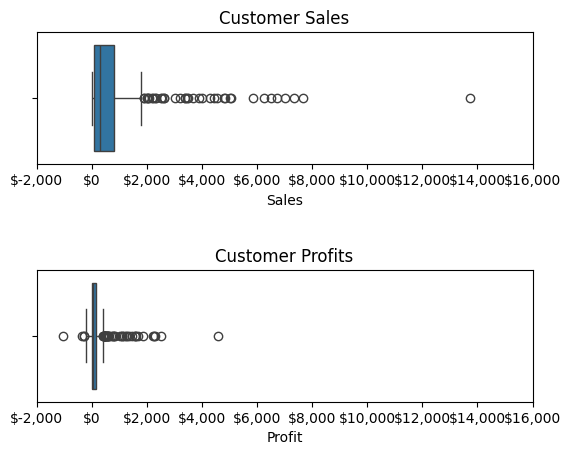

In [106]:
c_sales = customer_sales['Sales'].sort_values(ascending=False)
c_profit = customer_sales['Profit'].sort_values(ascending=False)
c_name = customer_sales['Customer ID'] + ' - ' + customer_sales['Customer Name']
metric = ['Sales', 'Profit']
print(f'total of {len(c_sales)} customers')

# Visualization as barplot
fig, (ax1, ax2) = plt.subplots(2, 1)

sns.boxplot(x=c_sales, ax=ax1)
# xticks label formatting
xticks = ax.get_xticks()
ax1.set_xticks(xticks) # Keeps current tick locations
ax1.set_xticklabels([f"${x:,.0f}" for x in xticks])
ax1.set_title('Customer Sales')

sns.boxplot(x=c_profit, ax=ax2)
# xticks label formatting
xticks = ax.get_xticks()
ax2.set_xticks(xticks) # Keeps current tick locations
ax2.set_xticklabels([f"${x:,.0f}" for x in xticks])
ax2.set_title('Customer Profits')

# Increase vertical space between the two subplots (Default is around 0.2)
plt.subplots_adjust(hspace=0.8)
plt.show()

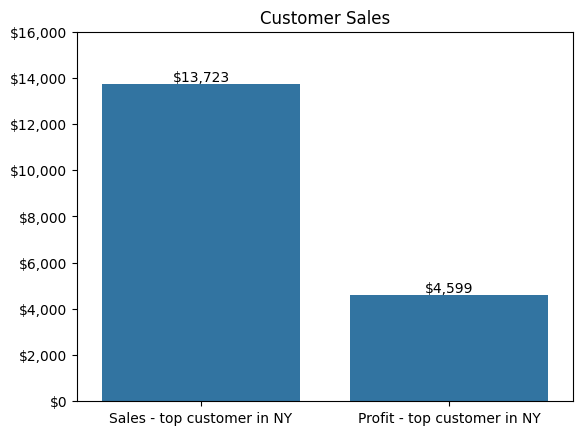

In [113]:
# top customer
category = ['Sales - top customer in NY','Profit - top customer in NY']
top_c = [customer_sales.sort_values(by = 'Sales', ascending=False)['Sales'][0],customer_sales.sort_values(by = 'Profit', ascending=False)['Profit'][0]]

ax = sns.barplot(x=category, y=top_c )
ax.bar_label(ax.containers[0], fmt = '${:,.0f}')

# yticks label formatting
# formatting y-ticks
yticks = ax.get_yticks()
ax.set_yticks(yticks) # Keeps current tick locations
ax.set_yticklabels([f"${y:,.0f}" for y in yticks])
ax.set_title('Customer Sales')

# plt.xticks(rotation=90
plt.show()

**Are there any differences among states in profitability?**



In [117]:
# transaction profitability
df['profit_margin'] = df['Profit']/df['Sales']

# overall profitability by state
states_sales['profit_margin'] = states_sales['Profit']/states_sales['Sales']
states_sales.sort_values(by='profit_margin', ascending=False).head()

,State,Sales,Profit,profit_margin
43,District of Columbia,2865.020,1059.5893,0.369837
21,Delaware,27451.069,9977.3748,0.363460
19,Minnesota,29863.150,10823.1874,0.362426
46,Maine,1270.530,454.4862,0.357714
30,Arkansas,11678.130,4008.6871,0.343264


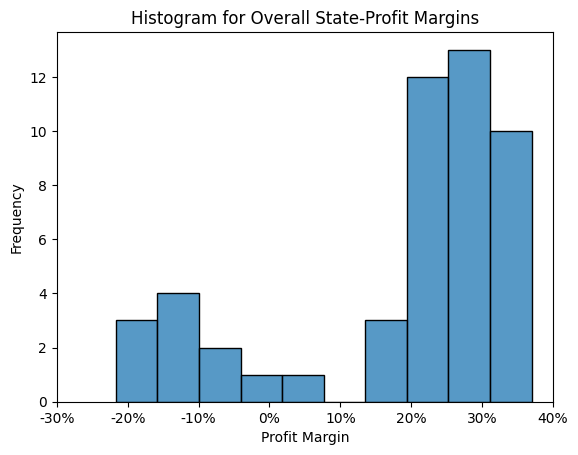

In [126]:
# plotting distribution of state-profitabilities:

ax = sns.histplot(data=states_sales, x='profit_margin', bins=10)
ax.set_title('Histogram for Overall State-Profit Margins')
ax.set_xlabel('Profit Margin')
ax.set_ylabel('Frequency')
xticks = ax.get_xticks()
ax.set_xticks(xticks) # Keeps current tick locations
ax.set_xticklabels([f"{x*100:.0f}%" for x in xticks])
plt.show()

The Pareto Principle, also known as the 80/20 rule, is a concept derived from the work of Italian economist Vilfredo Pareto.

It states that **roughly 80% of the effects come from 20% of the causes**. For instance, identifying the top 20% of products that generate 80% of sales or the top 20% of customers that contribute to 80% of profit can help in prioritizing efforts and resources.
This focus can lead to improved efficiency and effectiveness in business strategies.

Can we apply Pareto principle to customers and Profit ? (Determine if 20% of the customers contribute to 80% of the profit.)

In [186]:
customer_sales = df.groupby(['Customer ID','Customer Name','State'])[['Sales','Profit']].sum().sort_values(by = 'Sales', ascending=False).reset_index()
customer_sales

,Customer ID,Customer Name,State,Sales,Profit
0,SM-20320,Sean Miller,Florida,23661.228,-1789.7327
1,TC-20980,Tamara Chand,Indiana,18336.740,8762.3891
2,RB-19360,Raymond Buch,Washington,14052.480,6734.4720
3,TA-21385,Tom Ashbrook,New York,13723.498,4599.2073
4,BM-11140,Becky Martin,Texas,10539.896,-1878.7892
...,...,...,...,...,...
4058,TD-20995,Tamara Dahlen,Oregon,1.080,-0.7920
4059,HG-14965,Henry Goldwyn,Texas,0.876,-1.4016
4060,JO-15280,Jas O'Carroll,Pennsylvania,0.852,-0.5964
4061,KB-16600,Ken Brennan,Illinois,0.836,-1.3376


In [222]:
import ipywidgets as widgets
from ipywidgets import interact, Dropdown, IntSlider
from IPython.display import display
import matplotlib.ticker as mtick

In [237]:
total_profit = df['Profit'].sum()
total_sales = df['Sales'].sum()
customer_sales['profit_contrib'] = customer_sales['Profit']/total_profit
customer_sales['sales_contrib'] = customer_sales['Sales']/total_sales

In [261]:
from ipywidgets import FloatSlider
#metric = ['Sales', 'profit_contrib']


def pareto_check(topn_Q=0.2):
  topn = int(len(customer_sales)*topn_Q)
  print(f"checking {topn} customers")

  profit_contrib_sum = customer_sales.sort_values(by='profit_contrib', ascending=False).head(topn)['profit_contrib'].sum()
  #sales_contrib_sum = customer_sales.sort_values(by='Sales', ascending=False).head(topn)['Sales'].sum()

  plt.bar('profit', profit_contrib_sum)
  #ax.bar_label(ax.containers[0], fmt = '{:,.1%}')
  # Adds commas thousands separators and zero decimal places
  ax = plt.gca()
  ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
  # Add the value label to the bar (with dollar sign and commas)
  ax.bar_label(ax.containers[0], fmt='{:,.2%}', padding=3)

  plt.show()

# interactive slider for topn_Q using FloatSlider
topn_Q_slider = FloatSlider(min=0.01, max=1.0, step=0.01, value=0.20, description='Top n% customers:', readout_format='.0%')
interact(pareto_check, topn_Q=topn_Q_slider)

interactive(children=(FloatSlider(value=0.2, description='Top n% customers:', max=1.0, min=0.01, readout_forma…

<function __main__.pareto_check(topn_Q=0.2)>

**Answer**: Using the slider, once can see that already top 6-7% of customers contribute ca. 80% of overall Profit.


- What are the Top 20 cities by Sales ?
- What about the Top 20 cities by Profit ?
- Are there any difference among cities in profitability ?

(Identify the top 20 cities based on total sales and total profit and analyze differences in profitability among these cities.)

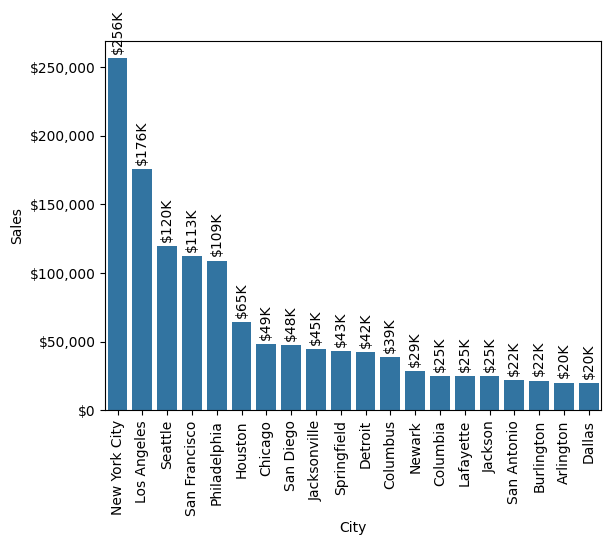

In [280]:
# top 20 most sales delivering cities:
city_df = df.groupby('City')[['Sales','Profit']].sum().sort_values(by = 'Sales', ascending=False).reset_index()
sns.barplot(data=city_df.head(20), x='City', y='Sales')
plt.xticks(rotation=90)

ax = plt.gca()

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))

# Format Bar Labels: Divide by 1000 dynamically
for container in ax.containers:
    labels = [f"${v/1000:,.0f}K" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, rotation=90)
# Add the value label to the bars (with dollar sign and commas)
# ax.bar_label(ax.containers[0], fmt='${:,,.0f}K', padding=3, rotation=90)

plt.show()

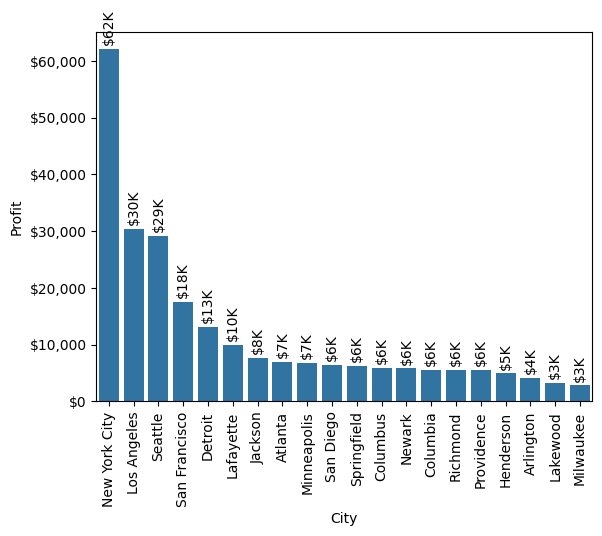

In [281]:
# top 20 most profit delivering cities:
city_df = df.groupby('City')[['Sales','Profit']].sum().sort_values(by = 'Profit', ascending=False).reset_index()
sns.barplot(data=city_df.head(20), x='City', y='Profit')
plt.xticks(rotation=90)

ax = plt.gca()

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))

# Format Bar Labels: Divide by 1000 dynamically
for container in ax.containers:
    labels = [f"${v/1000:,.0f}K" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, rotation=90)
# Add the value label to the bars (with dollar sign and commas)
# ax.bar_label(ax.containers[0], fmt='${:,,.0f}K', padding=3, rotation=90)

plt.show()

In [294]:
# checking different item level discounts offered:
df['Discount'].value_counts().reset_index()

,Discount,count
0,0.00,4798
1,0.20,3657
2,0.70,418
3,0.80,300
4,0.30,227
5,0.40,206
6,0.60,138
7,0.10,94
8,0.50,66
9,0.15,52


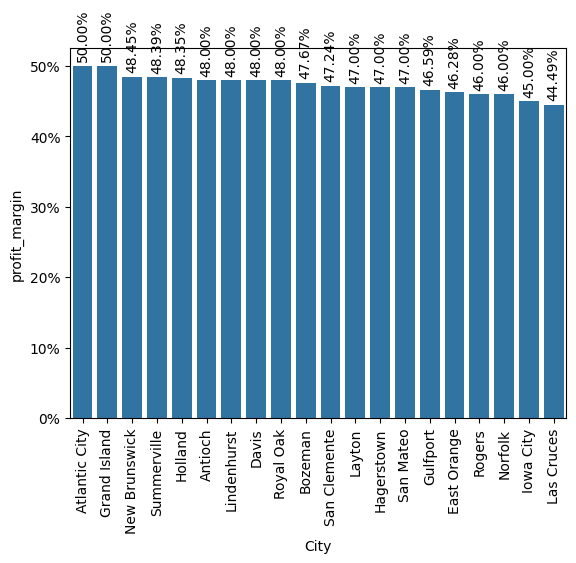

In [344]:
# top 20 cities by profitiability i.e. margin:
df['discount_usd'] = df['Discount']*df['Sales']
city_df = df.groupby('City')[['Sales','Profit','discount_usd']].sum().sort_values(by = 'Profit', ascending=False).reset_index()
city_df['profit_margin'] = city_df['Profit']/city_df['Sales']
city_df['discount_wavg_pct'] = city_df['discount_usd']/city_df['Sales']

sns.barplot(data=city_df.sort_values(by='profit_margin', ascending=False).head(20), x='City', y='profit_margin')
plt.xticks(rotation=90)

ax = plt.gca()
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1,decimals=0))

# Format Bar Labels: Divide by 1000 dynamically
for container in ax.containers:
    labels = [f"{v*100:,.2f}%" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, rotation=90)
# Add the value label to the bars (with dollar sign and commas)
# ax.bar_label(ax.containers[0], fmt='${:,,.0f}K', padding=3, rotation=90)

plt.show()

In [345]:
city_df.head(20)

,City,Sales,Profit,discount_usd,profit_margin,discount_wavg_pct
0,New York City,256368.161,62036.9837,20061.92370,0.241984,0.078254
1,Los Angeles,175851.341,30440.7579,21800.38495,0.173105,0.123971
2,Seattle,119540.742,29156.0967,8738.03040,0.243901,0.073097
3,San Francisco,112669.092,17507.3854,12957.58700,0.155388,0.115006
4,Detroit,42446.944,13181.7908,511.70940,0.310547,0.012055
5,Lafayette,25036.200,10018.3876,0.00000,0.400156,0.000000
6,Jackson,24963.858,7581.6828,672.43820,0.303706,0.026936
7,Atlanta,17197.840,6993.6629,0.00000,0.406659,0.000000
8,Minneapolis,16870.540,6824.5846,0.00000,0.404527,0.000000
9,San Diego,47521.029,6377.1960,6475.66635,0.134197,0.136269


In [295]:
# basic stats on profit margin and avg discount-% across cities
city_df.describe()

,Sales,Profit,discount_usd,profit_margin,discount_wavg_pct
count,531.000000,531.000000,531.000000,531.000000,531.000000
mean,4326.178645,539.354090,607.499311,0.115822,0.138366
std,16957.514408,3676.603852,2605.811158,0.322308,0.159960
min,1.392000,-13837.767400,0.000000,-2.700000,0.000000
25%,237.387000,4.176100,0.000000,0.034807,0.000000
50%,895.790000,73.352900,28.265600,0.186465,0.095239
75%,2655.923000,346.774250,281.350500,0.294066,0.219645
max,256368.161000,62036.983700,36331.389300,0.500000,0.800000


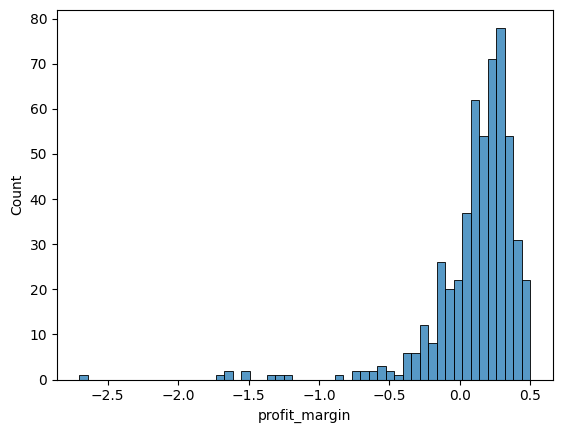

In [299]:
# histogram plot to visualize profit margin distribution:
sns.histplot(data=city_df, x='profit_margin', bins=int(len(df['City'].unique())/10))
plt.show()

In [300]:
print(f"skewness of profit margin distribution: {city_df['profit_margin'].skew():.2f}")
print(f"kurtosis of profit margin distribution: {city_df['profit_margin'].kurtosis():.2f}")

skewness of profit margin distribution: -3.45
kurtosis of profit margin distribution: 18.97


Conclusions on city's profitability:

- Top 5 most profitable cities (both margin and profit) are NY, LA, Seattle, San Francisco, Detroit.
- Top 5 by sales volume are same except Philadelphia replaces Detroit here. Philadelphia, however, isn't even among top 20 most profitable cities suggesting it's a highly discounted/subsidized city

- Majority of cities provide a profit margin between 0% and 50%, with overall range being from ca. [-270%, 50%]
- Overall, the distribution is left-skewed (negative skewness), i.e. with a heavier left tail due to cities with negative profits
- Kurtosis is high, i.e. more outliers than normal distribution.

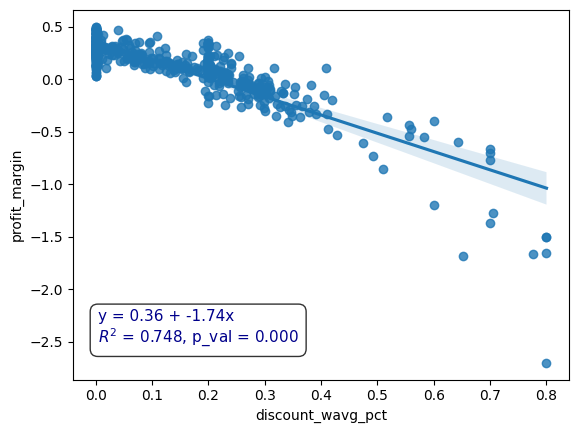

In [314]:
c

Protiability of a city for the supermarket is highly dependent on the average discounts offered: 3.6% decrease in profitability margin per extra 10% discounts. The relationship is highly significant

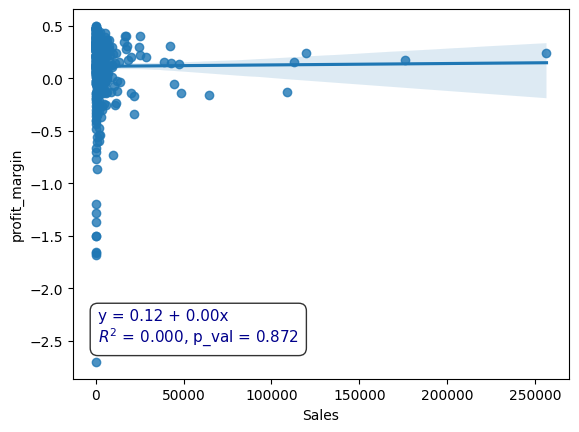

In [341]:
# relationship between Sales volume in a city and the its profitability margin:

reg_result = stats.linregress(city_df['Sales'], city_df['profit_margin'])

ax = sns.regplot(data=city_df, x='Sales', y='profit_margin')

# Add regression equation:
equation_text = f"y = {reg_result.intercept:.2f} + {reg_result.slope:.2f}x \n$R^2$ = {reg_result.rvalue**2:.3f}, p_val = {reg_result.pvalue:.3f}"

# Regression eq overlay onto the chart
ax.text(0.05, 0.10, equation_text, transform=ax.transAxes,
        fontsize=11, color="darkblue",
        bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

plt.show()

No relationship between sales volume and profitability of a location.

**What are the Top 20 customers by Sales?**

**Plot the Cumulative curve in Sales by Customers. Can we apply Pareto principle to customers and Sales ?**

checking 20 customers
0     0.010300
1     0.018282
2     0.024399
3     0.030373
4     0.034962
5     0.039532
6     0.043842
7     0.048148
8     0.052125
9     0.055958
10    0.059675
11    0.063306
12    0.066862
13    0.070204
14    0.073418
15    0.076621
16    0.079748
17    0.082795
18    0.085717
19    0.088544
Name: Sales, dtype: float64


(0.0, 0.10625236591985444)

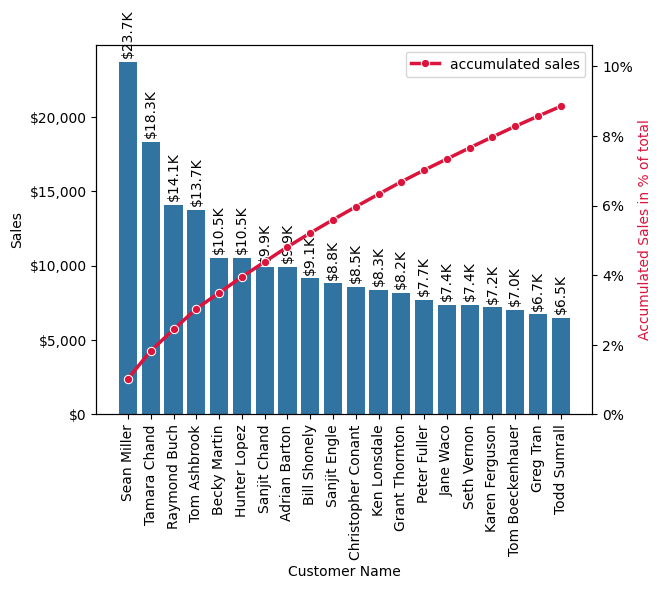

In [334]:
topn = 20

print(f"checking {topn} customers")

ax1 = sns.barplot(data=customer_sales.sort_values(by='Sales', ascending=False).head(topn), x='Customer Name', y='Sales')
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
# Format Bar Labels: Divide by 1000 dynamically
for container in ax1.containers:
    labels = [f"${v/1000:,.1f}K" for v in container.datavalues]
    ax1.bar_label(container, labels=labels, padding=3, rotation=90)

plt.xticks(rotation=90)

c_sales_accum = customer_sales.sort_values(by='Sales', ascending=False).head(topn)['Sales'].cumsum()/total_sales
print(c_sales_accum)

# Create the secondary axis and add a line plot for accumulated sales
ax2 = ax1.twinx()
sns.lineplot(x=customer_sales.sort_values(by='Sales', ascending=False).head(topn)['Customer Name'],y=c_sales_accum, color='crimson', marker='o', linewidth=2.5, ax=ax2, label='accumulated sales')
ax2.set_ylabel('Accumulated Sales in % of total', color='crimson')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))
ax2.set_ylim(0, max(c_sales_accum) * 1.2)




checking 812 customers


[Text(0, 0, ''),
 Text(1, 0, ''),
 Text(2, 0, ''),
 Text(3, 0, ''),
 Text(4, 0, ''),
 Text(5, 0, ''),
 Text(6, 0, ''),
 Text(7, 0, ''),
 Text(8, 0, ''),
 Text(9, 0, ''),
 Text(10, 0, ''),
 Text(11, 0, ''),
 Text(12, 0, ''),
 Text(13, 0, ''),
 Text(14, 0, ''),
 Text(15, 0, ''),
 Text(16, 0, ''),
 Text(17, 0, ''),
 Text(18, 0, ''),
 Text(19, 0, ''),
 Text(20, 0, ''),
 Text(21, 0, ''),
 Text(22, 0, ''),
 Text(23, 0, ''),
 Text(24, 0, ''),
 Text(25, 0, ''),
 Text(26, 0, ''),
 Text(27, 0, ''),
 Text(28, 0, ''),
 Text(29, 0, ''),
 Text(30, 0, ''),
 Text(31, 0, ''),
 Text(32, 0, ''),
 Text(33, 0, ''),
 Text(34, 0, ''),
 Text(35, 0, ''),
 Text(36, 0, ''),
 Text(37, 0, ''),
 Text(38, 0, ''),
 Text(39, 0, ''),
 Text(40, 0, ''),
 Text(41, 0, ''),
 Text(42, 0, ''),
 Text(43, 0, ''),
 Text(44, 0, ''),
 Text(45, 0, ''),
 Text(46, 0, ''),
 Text(47, 0, ''),
 Text(48, 0, ''),
 Text(49, 0, ''),
 Text(50, 0, ''),
 Text(51, 0, ''),
 Text(52, 0, ''),
 Text(53, 0, ''),
 Text(54, 0, ''),
 Text(55, 0, ''),
 T

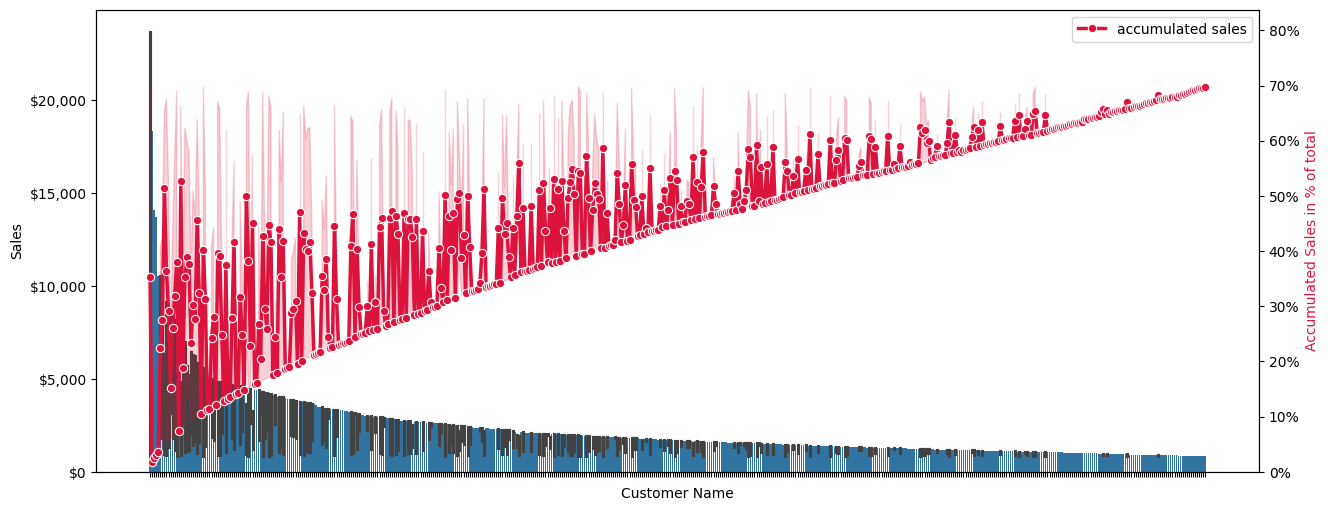

In [340]:
topn_Q = 0.2
topn = int(len(customer_sales)*topn_Q)

print(f"checking {topn} customers")

# stretching the plot size:
fig, ax1 = plt.subplots(figsize=(15, 6))

ax1 = sns.barplot(data=customer_sales.sort_values(by='Sales', ascending=False).head(topn), x='Customer Name', y='Sales')
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
# Format Bar Labels: Divide by 1000 dynamically
ax1.set_xticklabels([])

c_sales_accum = customer_sales.sort_values(by='Sales', ascending=False).head(topn)['Sales'].cumsum()/total_sales

# Create the secondary axis and add a line plot for accumulated sales
ax2 = ax1.twinx()
sns.lineplot(x=customer_sales.sort_values(by='Sales', ascending=False).head(topn)['Customer Name'],y=c_sales_accum, color='crimson', marker='o', linewidth=2.5, ax=ax2, label='accumulated sales')
ax2.set_ylabel('Accumulated Sales in % of total', color='crimson')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0, decimals=0))
ax2.set_ylim(0, max(c_sales_accum) * 1.2)
ax2.set_xticklabels([])

**Conclusion:** Pareto principle can't be applied for customer-sales,
- as top 20 customers contribute about 9% of sales (see chart)
- and event top 20% of the customers contribute around 70% of profits

**Based on the analysis, make decisions on which states and cities to prioritize for marketing strategies.**

In [355]:
print(city_df.sort_values(by='profit_margin', ascending=False).head(20)['City'].values)
print(city_df.sort_values(by='Profit', ascending=False).head(20)['City'].values)
for c in city_df.sort_values(by='profit_margin', ascending=False).head(20)['City'].values:
  print(f"Is city {c} also among top 20 by Profit volume? {c in city_df.sort_values(by='Profit', ascending=False).head(20)['City'].values}")

['Atlantic City' 'Grand Island' 'New Brunswick' 'Summerville' 'Holland'
 'Antioch' 'Lindenhurst' 'Davis' 'Royal Oak' 'Bozeman' 'San Clemente'
 'Layton' 'Hagerstown' 'San Mateo' 'Gulfport' 'East Orange' 'Rogers'
 'Norfolk' 'Iowa City' 'Las Cruces']
['New York City' 'Los Angeles' 'Seattle' 'San Francisco' 'Detroit'
 'Lafayette' 'Jackson' 'Atlanta' 'Minneapolis' 'San Diego' 'Springfield'
 'Columbus' 'Newark' 'Columbia' 'Richmond' 'Providence' 'Henderson'
 'Arlington' 'Lakewood' 'Milwaukee']
Is city Atlantic City also among top 20 by Profit volume? False
Is city Grand Island also among top 20 by Profit volume? False
Is city New Brunswick also among top 20 by Profit volume? False
Is city Summerville also among top 20 by Profit volume? False
Is city Holland also among top 20 by Profit volume? False
Is city Antioch also among top 20 by Profit volume? False
Is city Lindenhurst also among top 20 by Profit volume? False
Is city Davis also among top 20 by Profit volume? False
Is city Royal Oak al

**Conclusions:**
- It's better to invest in NY than CA as it's more profitable and has also big Sales volumes
- Among the cities better to focus on the high-margin ones, as currently none of these top20 is among the top 20 by profits volume generated. -> need to increase sales here